In [8]:
import numpy as np
from astropy.io import fits

import matplotlib.pyplot as plt

Filename: /home/gabrieleb/precov/data/ztf_cache/ztf_20210218313773_000366_zi_c03_o_q4_scimrefdiffimg.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   ()      
  1  4             1 CompImageHDU    279   (3072, 3080)   float32   
Filename: /home/gabrieleb/precov/data/ztf_cache/ztf_20210219338113_000366_zg_c07_o_q3_scimrefdiffimg.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   ()      
  1  3             1 CompImageHDU    271   (3072, 3080)   float32   


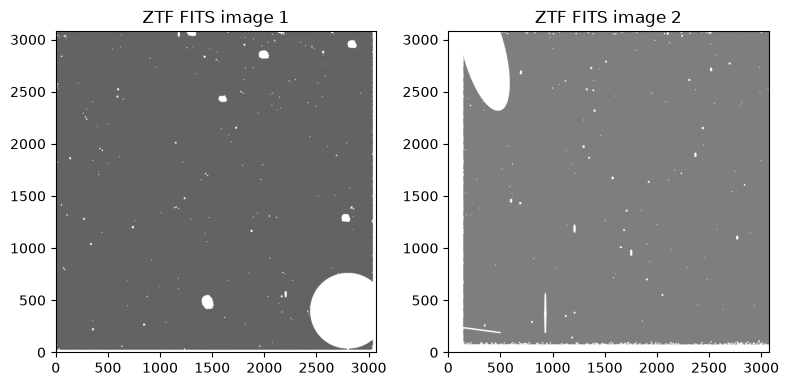

In [ ]:
hdul1 = fits.open('/home/gabrieleb/precov/data/ztf_cache/ztf_20210218313773_000366_zi_c03_o_q4_scimrefdiffimg.fits.fz')
hdul2 = fits.open('/home/gabrieleb/precov/data/ztf_cache/ztf_20210219338113_000366_zg_c07_o_q3_scimrefdiffimg.fits.fz')

# Check the structure of the file to see where the data lives
hdul1.info()
hdul2.info()

# Access the compressed image/data (frequently in index 1 instead of 0)
data1 = hdul1[1].data
data2 = hdul2[1].data
header1 = hdul1[1].header
header2 = hdul2[1].header

img1 = np.ma.masked_invalid(data1)
img2 = np.ma.masked_invalid(data2)

fig, ax = plt.subplots(1, 2, figsize=(8, 8))
im1 = ax[0].imshow(img1, origin='lower', cmap='gray')
ax[0].set_title('ZTF FITS image 1')
#fig.colorbar(im1, ax=ax[0], label='DN')

im2 = ax[1].imshow(img2, origin='lower', cmap='gray')
ax[1].set_title('ZTF FITS image 2')
#fig.colorbar(im2, ax=ax[1], label='DN')
plt.tight_layout()
plt.show()

hdul1.close()
hdul2.close()

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32                                                  NAXIS   =                    2                                                  NAXIS1  =                 3072                                                  NAXIS2  =                 3080                                                  BUNIT   = 'Data Value'                                                          ORIGIN  = 'Zwicky Transient Facility' / Data origin                             OBSERVER= 'ZTF Robotic Observing Software' / Observer                           ROBOSOFT= '1.0.3 December 21, 2020' / Robotic software version                  FITSSOFT= '1.0.3 December 21, 2020' / FITS software version                     INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                DETECTOR= '        '           / Detector controller                            DETSOFT = '        '           / Detecto

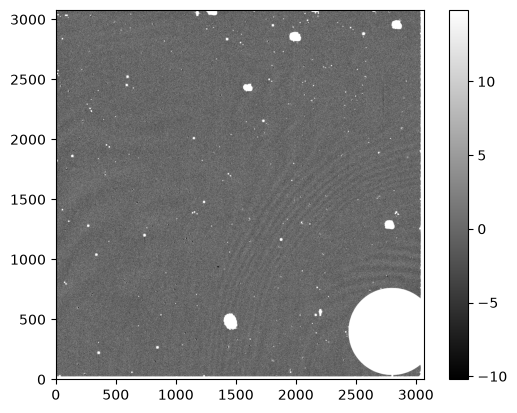

In [2]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

fn = "ztf_cache/ztf_20210218313773_000366_zi_c03_o_q4_scimrefdiffimg.fits"   # replace with one file from the manifest
h = fits.getheader(fn)
print(h)
img = fits.getdata(fn)
plt.imshow(img, cmap="gray", origin="lower", vmin=np.nanpercentile(img,5), vmax=np.nanpercentile(img,99))
plt.colorbar()
plt.show()

In [6]:
from astroquery.ipac.irsa import Irsa
from astropy.coordinates import SkyCoord
import astropy.units as u

coord = SkyCoord(ra=152.809421, dec=-13.346854, unit="deg")

# Query ZTF science-image metadata around a position
table = Irsa.query_region(coord, catalog="ztf_objects_dr23", spatial="Cone", radius=500*u.arcsec)

In [7]:
table

cntr,oid,ra,dec,htm20,field,ccdid,qid,fid,filtercode,x,y,z,ngoodobs,ngoodobsrel,nobs,nobsrel,refchi,refmag,refmagerr,refsharp,refsnr,astrometricrms,chisq,con,lineartrend,magrms,maxmag,maxslope,meanmag,medianabsdev,medianmag,medmagerr,minmag,nabovemeanbystd_1,nabovemeanbystd_3,nabovemeanbystd_5,nbelowmeanbystd_1,nbelowmeanbystd_3,nbelowmeanbystd_5,nconsecabovemeanbystd_1,nconsecabovemeanbystd_3,nconsecabovemeanbystd_5,nconsecbelowmeanbystd_1,nconsecbelowmeanbystd_3,nconsecbelowmeanbystd_5,nconsecfrommeanbystd_1,nconsecfrommeanbystd_3,nconsecfrommeanbystd_5,nmedianbufferrange,npairposslope,percentiles_05,percentiles_10,percentiles_175,percentiles_25,percentiles_325,percentiles_40,percentiles_60,percentiles_675,percentiles_75,percentiles_825,percentiles_90,percentiles_95,skewness,smallkurtosis,stetsonj,stetsonk,vonneumannratio,weightedmagrms,weightedmeanmag
,,deg,deg,,,,,,,,,,,,,,,mag,mag,,,deg,,,mag / d,mag,mag,mag / d,mag,mag,mag,mag,mag,,,,,,,,,,,,,,,,,,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,,,,,,mag,mag
int64,int64,float64,float64,int64,int32,int16,int16,int16,object,float64,float64,float64,int32,int32,int32,int32,float32,float32,float32,float32,float32,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32
366303400031792,366303400031792,152.7857523,-13.2630138,10539400955133,366,3,4,3,zi,-0.8655824641530306,0.445121091214853,-0.2294214722001099,0,0,0,0,0.634,22.074,0.332,-0.915,3.27,0,--,0,0,0,0,0,0,0,0,--,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
366303400022721,366303400022721,152.7868636,-13.2621488,10539400955650,366,3,4,3,zi,-0.8655941776089165,0.4451058862879066,-0.229406777758201,1,1,1,1,1.918,21.536,0.327,-0.149,3.32,0,0,0,0,--,20.3727,0,20.3727,0,20.3727,0.191399,20.3727,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,20.3727,0,0,0,0,0,--,--
366203400024988,366203400024988,152.7875294,-13.2624716,10539400957079,366,3,4,2,zr,-0.8655982004395931,0.44509523666733,-0.2294122614242567,0,0,0,0,0.576,22.478,0.283,-0.279,3.84,0,--,0,0,0,0,0,0,0,0,--,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
366203400005262,366203400005262,152.7863560,-13.2680249,10539400961701,366,3,4,2,zr,-0.8655693066621128,0.4451027932003944,-0.2295065987061726,3,3,4,3,1.009,22.129,0.253,-0.37,4.29,8.28693e-06,0,0,0,0.624293,21.246,0,20.85,0,21.1737,0.262563,20.1304,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,20.5477,20.3391,20.2496,20.2139,20.1946,20.1826,20.1652,20.1613,20.1582,20.1557,20.1536,20.1523,0,0,0,0,0,--,--
315213200031095,315213200031095,152.7864127,-13.2680599,10539400961708,315,13,2,2,zr,-0.8655696224571588,0.4451018725176463,-0.2295071932656065,0,0,0,0,1.417,21.89,0.236,0.058,4.59,0,--,0,0,0,0,0,0,0,0,--,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
366303400035123,366303400035123,152.7863950,-13.2681240,10539400961713,366,3,4,3,zi,-0.8655692566132958,0.4451020224920935,-0.229508282158519,2,1,2,1,1.422,21.416,0.251,-0.454,4.33,5.46543e-07,0,0,0,0.44397,20.4571,0,20.1431,0,20.1431,0.176241,19.8292,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19.9548,19.892,19.8651,19.8543,19.8485,19.8449,19.8396,19.8385,19.8376,19.8368,19.8362,19.8358,0,0,0,0,0,--,--
366203400029111,366203400029111,152.7939868,-13.2671822,10539400962462,366,3,4,2,zr,-0.8656315809464952,0.4449890537232156,-0.229492283387892,0,0,0,0,0.827,22.595,0.35,-0.545,3.1,0,--,0,0,0,0,0,0,0,0,--,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
366303400034578,366303400034578,152.7906183,-13.2685806,10539400964302,366,3,4,3,zi,-0.865600436324785,0.4450373834400745,-0.2295160386011265,0,0,0,0,0.726,22.119,0.346,-0.48,3.14

In [16]:
from astroquery.ipac.irsa.ibe import Ibe, IbeClass

ibe = IbeClass()
ibe.MISSION = 'ztf'
ibe.DATASET = 'products'
ibe.TABLE = 'sci'
images = ibe.query_region(coordinate=coord, mission='ztf')
print(images)  # gives file paths among other metadata

in_row_id   in_ra      in_dec   ...     dec4         ipac_pub_date      ipac_gid
                                ...     deg                                     
--------- ---------- ---------- ... ------------ ---------------------- --------
        1 152.809421 -13.346854 ... -13.56553828 2025-05-04 07:05:56+00        1
        1 152.809421 -13.346854 ... -13.58262761 2020-06-24 00:00:00+00        3
        1 152.809421 -13.346854 ... -14.12433229 2024-03-05 09:07:44+00        1
        1 152.809421 -13.346854 ...  -13.5527728 2026-09-10 04:33:23+00        2
        1 152.809421 -13.346854 ... -13.57086534 2024-07-14 05:07:57+00        1
        1 152.809421 -13.346854 ... -14.13081893 2026-08-12 05:43:22+00        2
        1 152.809421 -13.346854 ...  -14.1333395 2019-12-11 00:00:00+00        1
        1 152.809421 -13.346854 ...  -14.1505704 2019-12-11 00:00:00+00        1
        1 152.809421 -13.346854 ... -14.14981572 2019-05-08 00:00:00+00        1
      ...        ...        

200
in_row_id,in_ra,in_dec,filefracday,field,ccdid,qid,filtercode,imgtypecode,obsdate
1,152.80942099999999,-13.346854,20250305295799,366,3,4,zg,o,2025-03-05 07:05:57.964+00
1,152.80942099999999,-13.346854,20181213481181,366,3,4,zr,o,2018-12-13 11:32:54.702+00
1,152.80942099999999,-13.346854,20240105380312,315,13,2,zg,o,2024-01-05 09:07:45.178+00
1,152.80942099999999,-13.346854,20250309189850,366,3,4,zr,o,2025-03-09 04:33:24.425+00
1,152.80942099999999,-13.346854,20240515213843,366,3,4,zr,o,2024-05-15 05:07:57.123+00
1,152.80942099999999,-13.346854,20250208238125,315,13,2,zr,o,2025-02-08 05:43:23.081+00
1,152.80942099999999,-13.346854,20190104442361,315,13,2,zg,o,2019-01-04 10:37:00.724+00
1,152.80942099999999,-13.346854,20190414212014,315,13,2,zg,o,2019-04-14 05:05:18.297+00
1,152.80942099999999,-13.346854,20181220438947,315,13,2,zr,o,2018-12-20 10:32:06.371+00
1,152.80942099999999,-13.346854,20200216250405,315,13,2,zg,o,2020-02-16 06:00:36.38+00
1,152.80942099999999,-13.346854,2018121

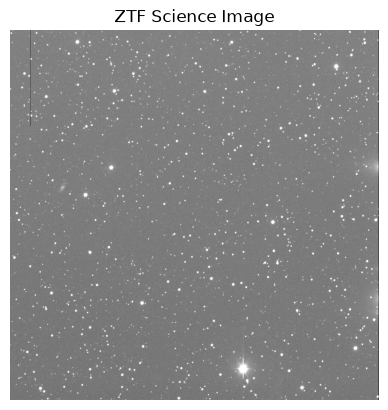

In [3]:
import requests
import pandas as pd
from io import StringIO
from astropy.io import fits
from astropy.visualization import ZScaleInterval, ImageNormalize
import matplotlib.pyplot as plt
from io import BytesIO

def ztf_sci_url(row, suffix="sciimg.fits"):
    """
    row: a dict-like object (e.g. a pandas Series) with at least:
         filefracday, field, filtercode, ccdid, imgtypecode, qid
    """
    filefracday = str(row["filefracday"])
    year    = filefracday[0:4]
    month   = filefracday[4:6]
    day     = filefracday[6:8]
    fracday = filefracday[8:14]

    paddedfield  = str(row["field"]).zfill(6)
    paddedccdid  = str(row["ccdid"]).zfill(2)
    filtercode   = row["filtercode"]
    imgtypecode  = row["imgtypecode"]
    qid          = row["qid"]

    base = "https://irsa.ipac.caltech.edu/ibe/data/ztf/products/sci"
    path = f"{base}/{year}/{month}{day}/{fracday}/ztf_{filefracday}_{paddedfield}_{filtercode}_c{paddedccdid}_{imgtypecode}_q{qid}_{suffix}"
    return path

# 1. Query metadata
url = "https://irsa.ipac.caltech.edu/ibe/search/ztf/products/sci"
params = {
    "POS": "152.809421,-13.346854",
    "SIZE": "0.01",
    "COLUMNS": "filefracday,field,ccdid,qid,filtercode,imgtypecode,obsdate",
    "ct": "csv"
}
r = requests.get(url, params=params)

print(r.status_code)
print(r.text[:2000]) 

df = pd.read_csv(StringIO(r.text))

# 2. Build image URL(s) from each row
df["image_url"] = df.apply(ztf_sci_url, axis=1)

# 3. Download & visualize the first match
img_url = df["image_url"].iloc[18]
r = requests.get(img_url)
hdul = fits.open(BytesIO(r.content))
data = hdul[0].data

norm = ImageNormalize(data, interval=ZScaleInterval())
plt.imshow(data, cmap="gray", origin="lower", norm=norm)
plt.title("ZTF Science Image")
plt.axis("off")
plt.show()